In [1]:
from google.colab import drive
drive.mount('/content/drive')

# Unzip once per session into local Colab storage (-q hides the 130-file printout)
!unzip -q "/content/drive/MyDrive/DronePropA Motion Trajectories Dataset.zip" -d /content/drone_data

Mounted at /content/drive


Using device: cuda
Loaded 130 files (9992 windows total)
File class counts [F0, F1, F2, F3]: [40 30 30 30]

Initialized Baseline 1D-CNN (Variant 1) | Learnable Parameters: 2852 | lr=0.01

########################################################################
OUTER FOLD 1/5 | Dev: 104 files [32 24 24 24] | Test: 26 files [8 6 6 6]
########################################################################

  [Outer 1 | Inner 1/5 | Run 1/25] Train: 83 files [25 19 20 19] | Val: 21 files [7 5 4 5]
    -> Best Val Loss: 0.9496 | Best Val Acc: 61.32% | Outer Test Acc: 65.79%

  [Outer 1 | Inner 2/5 | Run 2/25] Train: 83 files [25 20 19 19] | Val: 21 files [7 4 5 5]
    -> Best Val Loss: 0.8311 | Best Val Acc: 64.60% | Outer Test Acc: 63.44%

  [Outer 1 | Inner 3/5 | Run 3/25] Train: 83 files [26 19 19 19] | Val: 21 files [6 5 5 5]
    -> Best Val Loss: 0.7959 | Best Val Acc: 65.84% | Outer Test Acc: 66.82%

  [Outer 1 | Inner 4/5 | Run 4/25] Train: 83 files [26 19 19 19] | Val: 21 files [6 5

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/results/baseline_1dcnn_ch31_learning_curves.png'

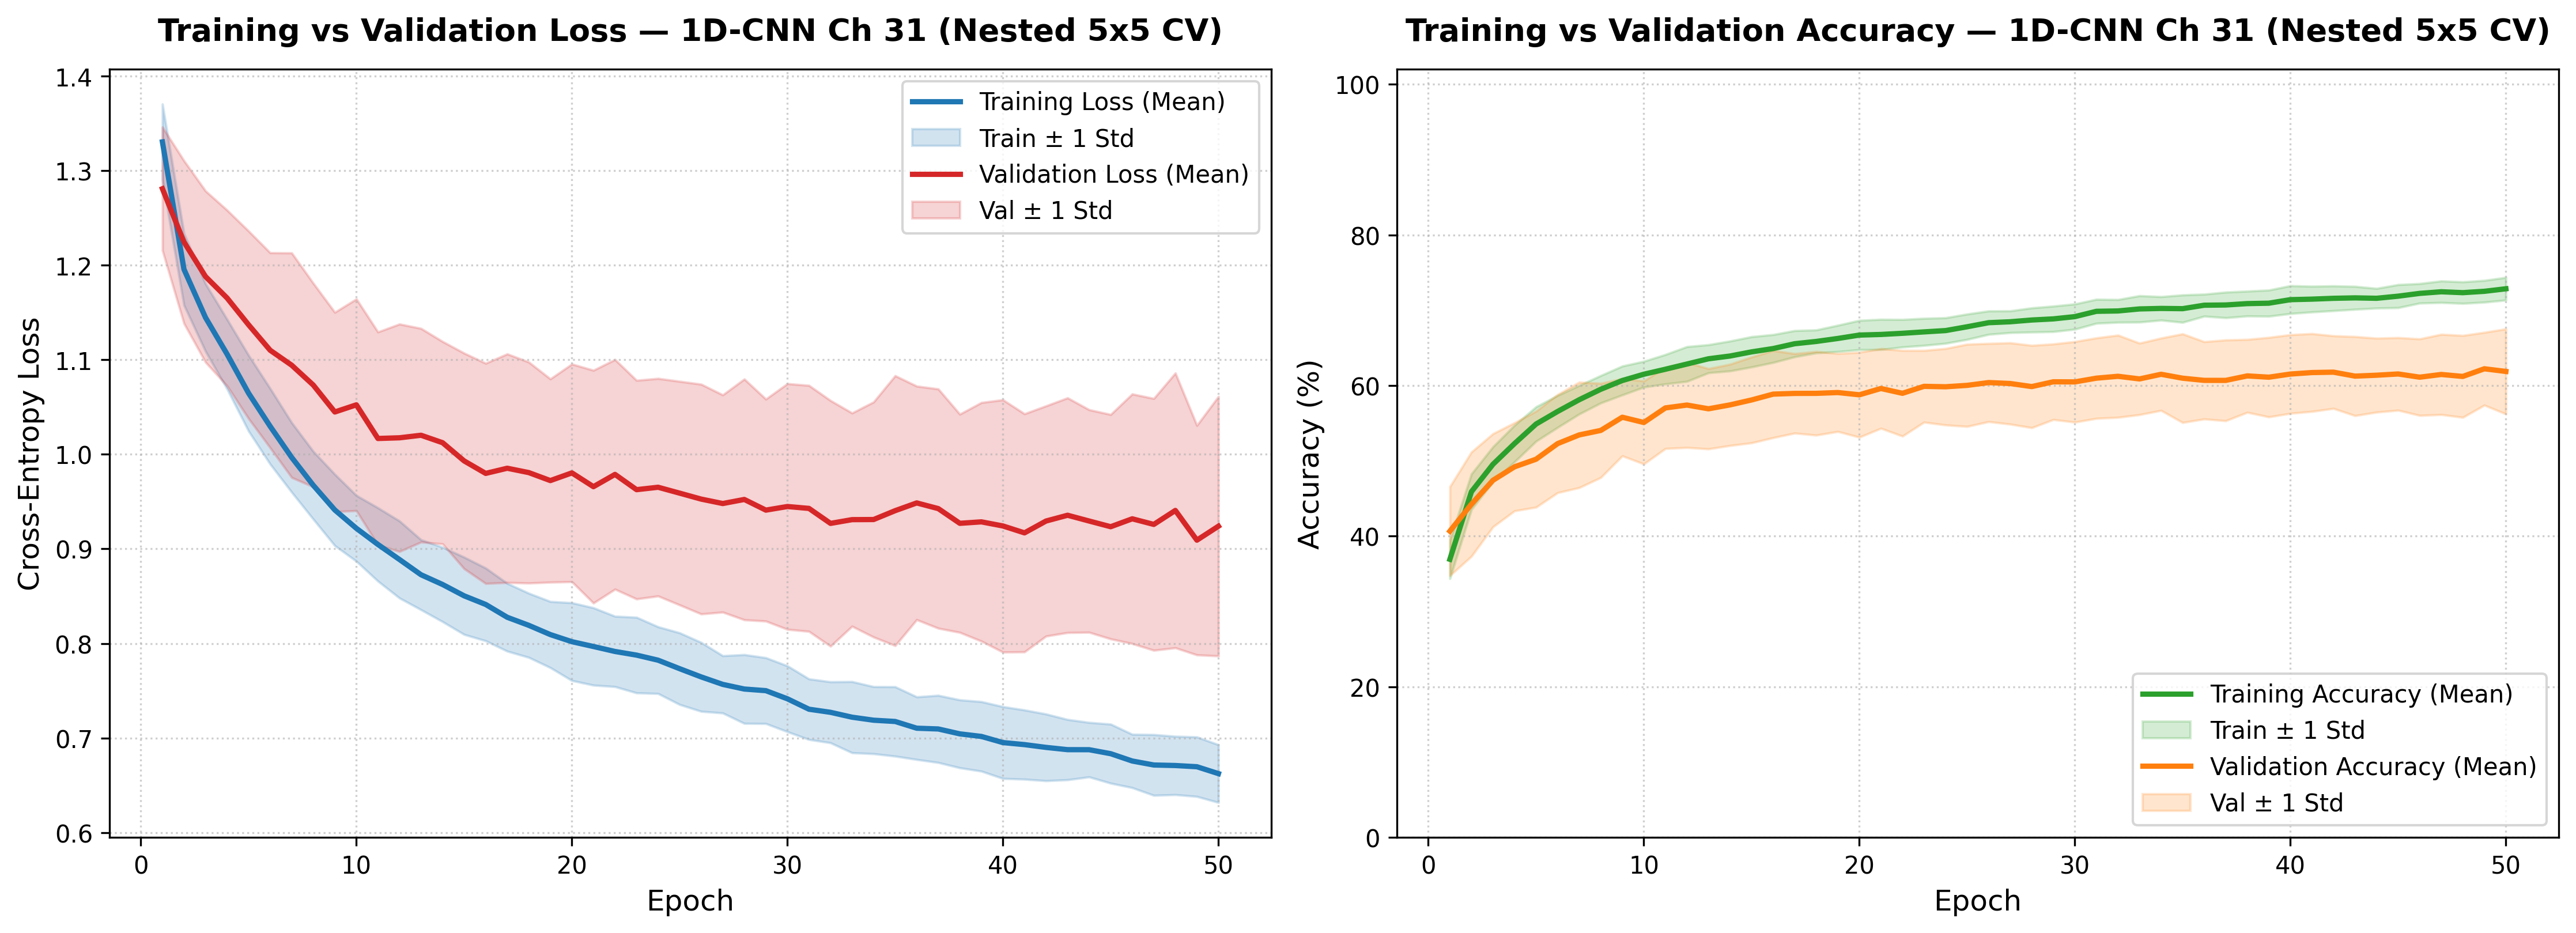

In [2]:
# =============================================================================
# 1. IMPORTS, DEVICE & HYPERPARAMETERS
# =============================================================================
import os
import glob
import copy
import numpy as np
import pandas as pd
import scipy.io as sio
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import StratifiedKFold
from sklearn.manifold import TSNE
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Path to DronePropA .mat files (e.g., "/content/drone_data" on Colab)
drone_dir = r"/content/drone_data"

# Hyperparameters
batch_size = 512
epochs = 50
lr = 0.01
weight_decay = 0.001
window_len = 1000
model_variant = 1       # 1: (16, 32) | 2: (32, 64) | 3: (64, 128)
num_classes = 4
eps = 1e-5

# Single channel only: Python index 31 (Accel Z from Accelerometer Unit #1)
target_indices = [31]
class_names = ["F0 (Healthy)", "F1 (Edge Cut)", "F2 (Crack)", "F3 (Surface Cut)"]


# =============================================================================
# 2. PREPROCESSING & FILE-GROUPED LOADING (STRICTLY FILE-LEVEL SPLITS)
# =============================================================================
def segment_and_mean_removal(signal_matrix, window_len=1000):
    """
    Segments a single flight into non-overlapping windows and removes per-window DC mean.
    Input:  signal_matrix -> (1, N_samples)
    Output: np.ndarray    -> (num_windows, 1, window_len), float32
    """
    total_samples = signal_matrix.shape[1]
    num_windows = total_samples // window_len
    windows = []

    for i in range(num_windows):
        k_start = i * window_len
        k_end = (i + 1) * window_len
        segment = signal_matrix[:, k_start:k_end].astype(np.float32)
        mean_val = np.mean(segment, axis=1, keepdims=True)   # (1, 1)
        normalized_segment = segment - mean_val              # (1, window_len)
        windows.append(normalized_segment)

    return np.array(windows, dtype=np.float32)


def load_files_grouped(data_dir, target_indices, window_len=1000):
    """
    Loads all 130 .mat files ONCE outside the CV loops, keeping each flight's
    windows grouped separately so outer and inner splits never leak windows across flights.
    """
    mat_files = sorted(glob.glob(os.path.join(data_dir, "**", "*.mat"), recursive=True))
    assert len(mat_files) > 0, f"No .mat files found in '{data_dir}'. Check drone_dir."

    file_windows_list = []
    file_labels = []

    for fpath in mat_files:
        basename = os.path.basename(fpath)
        label = int(basename[1])                             # F0->0, F1->1, F2->2, F3->3

        mat = sio.loadmat(fpath)
        selected = mat["QDrone_data"][target_indices, :]     # (1, N_samples)
        segments = segment_and_mean_removal(selected, window_len=window_len)

        file_windows_list.append(segments)
        file_labels.append(label)

    file_labels = np.array(file_labels, dtype=np.int64)
    total_windows = sum(len(w) for w in file_windows_list)
    print(f"Loaded {len(file_labels)} files ({total_windows} windows total)")
    print(f"File class counts [F0, F1, F2, F3]: {np.bincount(file_labels, minlength=num_classes)}")
    return file_windows_list, file_labels


def concat_selected_files(file_indices, file_windows_list, file_labels):
    """Concatenates windows strictly from the given disjoint file indices."""
    X = np.concatenate([file_windows_list[i] for i in file_indices], axis=0)
    y = np.concatenate([
        np.full(len(file_windows_list[i]), file_labels[i], dtype=np.int64)
        for i in file_indices
    ], axis=0)
    return X, y


class VibrationDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.from_numpy(X).float()
        self.y = torch.from_numpy(y).long()

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


# =============================================================================
# 3. SINGLE-BRANCH 1D-CNN ARCHITECTURE (CAUSAL CONV + LAYERNORM)
# =============================================================================
class CausalConv1d(nn.Module):
    """
    1D Causal Convolution with bias=True.
    Left-pads by (kernel_size - 1) * dilation so timestep t only depends on <= t.
    Shape: (B, C_in, L) -> (B, C_out, L)
    """
    def __init__(self, in_channels, out_channels, kernel_size, stride=1, dilation=1):
        super().__init__()
        self.causal_padding = (kernel_size - 1) * dilation
        self.conv = nn.Conv1d(
            in_channels=in_channels,
            out_channels=out_channels,
            kernel_size=kernel_size,
            stride=stride,
            padding=0,
            dilation=dilation,
            bias=True,
        )

    def forward(self, x):
        x = F.pad(x, (self.causal_padding, 0))   # (B, C_in, L + causal_padding)
        return self.conv(x)                      # (B, C_out, L)


class ChannelLayerNorm1d(nn.Module):
    """
    Channel-wise LayerNorm applied across C at each timestep independently.
    Shape: (B, C, L) -> (B, L, C) -> LayerNorm(C) -> (B, C, L)
    """
    def __init__(self, num_channels, eps=1e-5):
        super().__init__()
        self.norm = nn.LayerNorm(num_channels, eps=eps, elementwise_affine=False)

    def forward(self, x):
        x = x.transpose(1, 2)                    # (B, L, C)
        x = self.norm(x)                         # (B, L, C)
        return x.transpose(1, 2)                 # (B, C, L)


class DronePropeller1DCNN(nn.Module):
    def __init__(self, in_channels=1, num_classes=4, model_variant=1, eps=1e-5):
        super().__init__()
        variant_map = {
            1: (16, 32),
            2: (32, 64),
            3: (64, 128),
        }
        if model_variant not in variant_map:
            raise ValueError("model_variant must be 1, 2, or 3.")

        c1, c2 = variant_map[model_variant]

        self.conv1 = CausalConv1d(in_channels, c1, kernel_size=7, stride=1)  # (B, c1, 1000)
        self.relu1 = nn.ReLU()
        self.ln1 = ChannelLayerNorm1d(c1, eps=eps)
        self.pool1 = nn.AvgPool1d(kernel_size=4, stride=4, padding=0)        # (B, c1, 250)

        self.conv2 = CausalConv1d(c1, c2, kernel_size=5, stride=1)           # (B, c2, 250)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.AvgPool1d(kernel_size=4, stride=4, padding=0)        # (B, c2, 62)
        self.ln2 = ChannelLayerNorm1d(c2, eps=eps)

        self.global_pool = nn.AdaptiveAvgPool1d(1)                           # (B, c2, 1)
        self.fc = nn.Linear(c2, num_classes, bias=True)                      # (B, num_classes)

    def extract_features(self, x):
        x = self.conv1(x)                        # (B, c1, 1000)
        x = self.relu1(x)
        x = self.ln1(x)
        x = self.pool1(x)                        # (B, c1, 250)

        x = self.conv2(x)                        # (B, c2, 250)
        x = self.relu2(x)
        x = self.pool2(x)                        # (B, c2, 62)
        x = self.ln2(x)

        x = self.global_pool(x)                  # (B, c2, 1)
        return x.squeeze(-1)                     # (B, c2)

    def forward(self, x):
        feats = self.extract_features(x)         # (B, c2)
        return self.fc(feats)                    # (B, num_classes)


def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


# =============================================================================
# 4. NESTED 5x5 STRATIFIED CROSS-VALIDATION (104/26 OUTER, ~83/~21 INNER)
# =============================================================================
def run_nested_5x5_cv(
    file_windows_list,
    file_labels,
    model_fn,
    batch_size=512,
    epochs=50,
    lr=0.01,
    weight_decay=0.001,
    num_classes=4,
    device=device
):
    outer_skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    all_file_idx = np.arange(len(file_labels))
    pin_mem = (device.type == "cuda")

    sample_model = model_fn()
    print(f"\nInitialized Baseline 1D-CNN (Variant {model_variant}) | "
          f"Learnable Parameters: {count_parameters(sample_model)} | lr={lr}")
    del sample_model

    seen_outer_test_files = set()
    outer_ensemble_accs = []
    outer_mean_inner_accs = []
    oof_true = []
    oof_preds = []

    # Epoch curves across all 25 runs: shape (25, epochs)
    history = {
        "train_loss": np.zeros((25, epochs), dtype=np.float64),
        "val_loss":   np.zeros((25, epochs), dtype=np.float64),
        "train_acc":  np.zeros((25, epochs), dtype=np.float64),
        "val_acc":    np.zeros((25, epochs), dtype=np.float64),
    }

    # Tracks single best-val-loss model's unseen test features for clean single-space t-SNE
    best_overall_val_loss = float("inf")
    tsne_bundle = {"features": None, "targets": None, "tag": ""}

    # --- OUTER 5-FOLD LOOP (104 dev / 26 unseen test files) ---
    for outer_fold, (dev_idx, test_idx) in enumerate(outer_skf.split(all_file_idx, file_labels), start=1):
        assert seen_outer_test_files.isdisjoint(test_idx), "Outer test files leaked across folds!"
        seen_outer_test_files.update(test_idx)

        print(f"\n{'#'*72}")
        print(f"OUTER FOLD {outer_fold}/5 | Dev: {len(dev_idx)} files {np.bincount(file_labels[dev_idx], minlength=num_classes)} "
              f"| Test: {len(test_idx)} files {np.bincount(file_labels[test_idx], minlength=num_classes)}")
        print(f"{'#'*72}")

        X_test, y_test = concat_selected_files(test_idx, file_windows_list, file_labels)
        test_loader = DataLoader(
            VibrationDataset(X_test, y_test),
            batch_size=batch_size, shuffle=False, pin_memory=pin_mem
        )

        outer_test_probs_sum = np.zeros((len(y_test), num_classes), dtype=np.float64)
        inner_val_accs = []
        inner_test_accs = []

        # --- INNER 5-FOLD LOOP (Inside the 104 dev files -> ~83 train / ~21 val) ---
        inner_skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=100 + outer_fold)
        seen_inner_val_files = set()

        for inner_fold, (inner_train_pos, inner_val_pos) in enumerate(
            inner_skf.split(dev_idx, file_labels[dev_idx]), start=1
        ):
            run_idx = (outer_fold - 1) * 5 + (inner_fold - 1)  # 0..24

            # Map relative positions (0..103) back to global file indices (0..129)
            train_idx = dev_idx[inner_train_pos]
            val_idx = dev_idx[inner_val_pos]

            # Strict zero-leakage checks
            assert set(train_idx).isdisjoint(val_idx)
            assert set(train_idx).isdisjoint(test_idx)
            assert set(val_idx).isdisjoint(test_idx)
            assert seen_inner_val_files.isdisjoint(val_idx)
            seen_inner_val_files.update(val_idx)

            print(f"\n  [Outer {outer_fold} | Inner {inner_fold}/5 | Run {run_idx + 1}/25] "
                  f"Train: {len(train_idx)} files {np.bincount(file_labels[train_idx], minlength=num_classes)} | "
                  f"Val: {len(val_idx)} files {np.bincount(file_labels[val_idx], minlength=num_classes)}")

            X_train, y_train = concat_selected_files(train_idx, file_windows_list, file_labels)
            X_val, y_val = concat_selected_files(val_idx, file_windows_list, file_labels)

            train_loader = DataLoader(
                VibrationDataset(X_train, y_train),
                batch_size=batch_size, shuffle=True, pin_memory=pin_mem
            )
            val_loader = DataLoader(
                VibrationDataset(X_val, y_val),
                batch_size=batch_size, shuffle=False, pin_memory=pin_mem
            )

            # Fresh model & optimizer for each of the 25 runs
            torch.manual_seed(42 + run_idx)
            model = model_fn().to(device)
            criterion = nn.CrossEntropyLoss()
            optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

            best_val_loss = float("inf")
            best_val_acc = 0.0
            best_weights = copy.deepcopy(model.state_dict())

            # --- Training & Validation Epochs ---
            for epoch in range(epochs):
                model.train()
                t_loss_sum = 0.0
                t_correct = 0

                for inputs, targets in train_loader:
                    inputs = inputs.to(device, non_blocking=pin_mem)
                    targets = targets.to(device, non_blocking=pin_mem)

                    optimizer.zero_grad()
                    logits = model(inputs)
                    loss = criterion(logits, targets)
                    loss.backward()
                    optimizer.step()

                    t_loss_sum += loss.item() * targets.size(0)
                    t_correct += (logits.argmax(dim=1) == targets).sum().item()

                train_loss = t_loss_sum / len(train_loader.dataset)
                train_acc = t_correct / len(train_loader.dataset)

                model.eval()
                v_loss_sum = 0.0
                v_correct = 0

                with torch.no_grad():
                    for inputs, targets in val_loader:
                        inputs = inputs.to(device, non_blocking=pin_mem)
                        targets = targets.to(device, non_blocking=pin_mem)

                        logits = model(inputs)
                        loss = criterion(logits, targets)

                        v_loss_sum += loss.item() * targets.size(0)
                        v_correct += (logits.argmax(dim=1) == targets).sum().item()

                val_loss = v_loss_sum / len(val_loader.dataset)
                val_acc = v_correct / len(val_loader.dataset)

                history["train_loss"][run_idx, epoch] = train_loss
                history["val_loss"][run_idx, epoch] = val_loss
                history["train_acc"][run_idx, epoch] = train_acc
                history["val_acc"][run_idx, epoch] = val_acc

                if val_loss < best_val_loss:
                    best_val_loss = val_loss
                    best_val_acc = val_acc
                    best_weights = copy.deepcopy(model.state_dict())

            inner_val_accs.append(best_val_acc)

            # --- Evaluate Best Inner Checkpoint on Outer 26 Unseen Test Files ---
            model.load_state_dict(best_weights)
            model.eval()
            probs_list = []
            capture_tsne = (best_val_loss < best_overall_val_loss)
            feats_list = []

            with torch.no_grad():
                for inputs, _ in test_loader:
                    inputs = inputs.to(device, non_blocking=pin_mem)

                    feats = model.extract_features(inputs)   # (B, c2)
                    logits = model.fc(feats)                 # (B, 4)
                    probs_list.append(F.softmax(logits, dim=1).cpu().numpy())

                    if capture_tsne:
                        feats_list.append(feats.cpu().numpy())

            if capture_tsne:
                best_overall_val_loss = best_val_loss
                tsne_bundle["features"] = np.concatenate(feats_list, axis=0)
                tsne_bundle["targets"] = y_test.copy()
                tsne_bundle["tag"] = f"Outer Fold {outer_fold} / Inner Fold {inner_fold}"

            inner_test_probs = np.concatenate(probs_list, axis=0)
            inner_test_acc = accuracy_score(y_test, inner_test_probs.argmax(axis=1))
            inner_test_accs.append(inner_test_acc)
            outer_test_probs_sum += inner_test_probs

            print(f"    -> Best Val Loss: {best_val_loss:.4f} | Best Val Acc: {best_val_acc*100:.2f}% "
                  f"| Outer Test Acc: {inner_test_acc*100:.2f}%")

            del model, optimizer, train_loader, val_loader
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

        assert len(seen_inner_val_files) == len(dev_idx)

        outer_preds = outer_test_probs_sum.argmax(axis=1)
        outer_ens_acc = accuracy_score(y_test, outer_preds)
        outer_mean_acc = float(np.mean(inner_test_accs))

        outer_ensemble_accs.append(outer_ens_acc)
        outer_mean_inner_accs.append(outer_mean_acc)
        oof_true.extend(y_test)
        oof_preds.extend(outer_preds)

        print(f"\n>>> OUTER FOLD {outer_fold} SUMMARY:")
        print(f"    Inner Val Accs:         {[round(a*100, 2) for a in inner_val_accs]} (Mean: {np.mean(inner_val_accs)*100:.2f}%)")
        print(f"    Mean Single-Model Test: {outer_mean_acc*100:.2f}% +/- {np.std(inner_test_accs)*100:.2f}%")
        print(f"    5-Model Ensemble Test:  {outer_ens_acc*100:.2f}%")

        del test_loader

    assert len(seen_outer_test_files) == len(file_labels)

    outer_mean_inner_accs = np.array(outer_mean_inner_accs)
    outer_ensemble_accs = np.array(outer_ensemble_accs)

    print(f"\n{'='*72}")
    print(f"FINAL NESTED 5x5 CV RESULTS — Baseline 1D-CNN (Ch 31 Only, Variant {model_variant})")
    print(f"Per-Fold Mean Single-Model Test Acc: {[round(a*100, 2) for a in outer_mean_inner_accs]}")
    print(f"Overall Single-Model Test Acc:       {outer_mean_inner_accs.mean()*100:.2f}% +/- {outer_mean_inner_accs.std()*100:.2f}%")
    print(f"Per-Fold 5-Model Ensemble Test Acc:  {[round(a*100, 2) for a in outer_ensemble_accs]}")
    print(f"Overall 5-Model Ensemble Test Acc:   {outer_ensemble_accs.mean()*100:.2f}% +/- {outer_ensemble_accs.std()*100:.2f}%")
    print(f"{'='*72}")

    return outer_mean_inner_accs, outer_ensemble_accs, np.array(oof_true), np.array(oof_preds), history, tsne_bundle


# =============================================================================
# 5. VISUALIZATIONS (LEARNING CURVES, CONFUSION MATRIX, REPORT, t-SNE)
# =============================================================================
def plot_learning_curves(history, save_path="baseline_1dcnn_ch31_learning_curves.png"):
    """Plots Mean +/- 1 Std Training & Validation Loss and Accuracy across all 25 runs."""
    epochs_axis = np.arange(1, history["train_loss"].shape[1] + 1)

    t_loss_mean, t_loss_std = history["train_loss"].mean(axis=0), history["train_loss"].std(axis=0)
    v_loss_mean, v_loss_std = history["val_loss"].mean(axis=0),   history["val_loss"].std(axis=0)
    t_acc_mean,  t_acc_std  = history["train_acc"].mean(axis=0) * 100, history["train_acc"].std(axis=0) * 100
    v_acc_mean,  v_acc_std  = history["val_acc"].mean(axis=0) * 100,   history["val_acc"].std(axis=0) * 100

    fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), dpi=300)

    # Loss curves
    axes[0].plot(epochs_axis, t_loss_mean, color="#1f77b4", linewidth=2.2, label="Training Loss (Mean)")
    axes[0].fill_between(epochs_axis, t_loss_mean - t_loss_std, t_loss_mean + t_loss_std,
                         color="#1f77b4", alpha=0.2, label="Train ± 1 Std")
    axes[0].plot(epochs_axis, v_loss_mean, color="#d62728", linewidth=2.2, label="Validation Loss (Mean)")
    axes[0].fill_between(epochs_axis, v_loss_mean - v_loss_std, v_loss_mean + v_loss_std,
                         color="#d62728", alpha=0.2, label="Val ± 1 Std")
    axes[0].set_title("Training vs Validation Loss — 1D-CNN Ch 31 (Nested 5x5 CV)", fontsize=13, fontweight="bold", pad=12)
    axes[0].set_xlabel("Epoch", fontsize=12)
    axes[0].set_ylabel("Cross-Entropy Loss", fontsize=12)
    axes[0].grid(True, linestyle=":", alpha=0.6)
    axes[0].legend(fontsize=10)

    # Accuracy curves
    axes[1].plot(epochs_axis, t_acc_mean, color="#2ca02c", linewidth=2.2, label="Training Accuracy (Mean)")
    axes[1].fill_between(epochs_axis,
                         np.clip(t_acc_mean - t_acc_std, 0, 100),
                         np.clip(t_acc_mean + t_acc_std, 0, 100),
                         color="#2ca02c", alpha=0.2, label="Train ± 1 Std")
    axes[1].plot(epochs_axis, v_acc_mean, color="#ff7f0e", linewidth=2.2, label="Validation Accuracy (Mean)")
    axes[1].fill_between(epochs_axis,
                         np.clip(v_acc_mean - v_acc_std, 0, 100),
                         np.clip(v_acc_mean + v_acc_std, 0, 100),
                         color="#ff7f0e", alpha=0.2, label="Val ± 1 Std")
    axes[1].set_title("Training vs Validation Accuracy — 1D-CNN Ch 31 (Nested 5x5 CV)", fontsize=13, fontweight="bold", pad=12)
    axes[1].set_xlabel("Epoch", fontsize=12)
    axes[1].set_ylabel("Accuracy (%)", fontsize=12)
    axes[1].set_ylim(0, 102)
    axes[1].grid(True, linestyle=":", alpha=0.6)
    axes[1].legend(loc="lower right", fontsize=10)

    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    print(f"Saved learning curves to: {save_path}")
    plt.show()


def plot_colorful_metrics(
    y_true,
    y_pred,
    class_names,
    cm_path="baseline_1dcnn_ch31_confusion_matrix.png",
    cr_path="baseline_1dcnn_ch31_classification_report.png"
):
    # 1. Colorful Confusion Matrix
    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(8, 6.5), dpi=300)
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
        square=True,
        linewidths=0.6,
        cbar_kws={"shrink": 0.8}
    )
    plt.title("Confusion Matrix — Baseline 1D-CNN Ch 31 (Nested 5x5 CV)", fontsize=13, fontweight="bold", pad=15)
    plt.xlabel("Predicted Fault Class", fontsize=12)
    plt.ylabel("True Fault Class", fontsize=12)
    plt.xticks(rotation=30, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.savefig(cm_path, dpi=300, bbox_inches="tight")
    print(f"Saved confusion matrix to: {cm_path}")
    plt.show()

    # 2. Colorful Classification Report Heatmap
    report_dict = classification_report(y_true, y_pred, target_names=class_names, output_dict=True)
    df_report = pd.DataFrame(report_dict).transpose()

    supports = df_report["support"].copy()
    df_metrics = df_report.drop("support", axis=1)
    y_labels = [
        f"{row} (n={int(supports[row])})" if row != "accuracy" else f"accuracy (n={len(y_true)})"
        for row in df_metrics.index
    ]

    plt.figure(figsize=(9, 6.5), dpi=300)
    sns.heatmap(
        df_metrics,
        annot=True,
        fmt=".4f",
        cmap="viridis",
        vmin=0.0,
        vmax=1.0,
        yticklabels=y_labels,
        linewidths=0.6,
        cbar_kws={"shrink": 0.85}
    )
    plt.title("Classification Report — Baseline 1D-CNN Ch 31 (Nested 5x5 CV)", fontsize=13, fontweight="bold", pad=15)
    plt.xticks(fontsize=11)
    plt.yticks(rotation=0, fontsize=10)
    plt.tight_layout()
    plt.savefig(cr_path, dpi=300, bbox_inches="tight")
    print(f"Saved classification report to: {cr_path}")
    plt.show()


def plot_tsne_from_bundle(tsne_bundle, class_names, save_path="baseline_1dcnn_ch31_tsne.png"):
    """Plots 2D t-SNE of unseen test features from the single lowest-val-loss checkpoint."""
    features = tsne_bundle["features"]
    targets = tsne_bundle["targets"]
    tag = tsne_bundle["tag"]

    print(f"Computing t-SNE on {features.shape} features from {tag}...")
    tsne = TSNE(n_components=2, perplexity=30, max_iter=1000, init="pca", learning_rate="auto", random_state=42)
    features_2d = tsne.fit_transform(features)

    colors = ["#2ca02c", "#ff7f0e", "#1f77b4", "#d62728"]

    plt.figure(figsize=(11, 8), dpi=300)
    for class_idx, (class_name, color) in enumerate(zip(class_names, colors)):
        mask = (targets == class_idx)
        plt.scatter(
            features_2d[mask, 0],
            features_2d[mask, 1],
            c=color,
            label=class_name,
            alpha=0.7,
            edgecolors="w",
            linewidth=0.5,
            s=30
        )

    plt.title(f"t-SNE of Baseline 1D-CNN (Ch 31) Features ({tag}, Unseen Test Flights)",
              fontsize=13, fontweight="bold", pad=14)
    plt.xlabel("t-SNE Dimension 1", fontsize=12)
    plt.ylabel("t-SNE Dimension 2", fontsize=12)
    plt.legend(title="Propeller States", title_fontsize=12, fontsize=11)
    plt.grid(True, linestyle=":", alpha=0.6)
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    print(f"Saved t-SNE plot to: {save_path}")
    plt.show()


# =============================================================================
# 6. EXECUTE FULL BASELINE PIPELINE
# =============================================================================
file_windows_list, file_labels = load_files_grouped(
    data_dir=drone_dir,
    target_indices=target_indices,
    window_len=window_len
)

mean_single_accs, ensemble_accs, y_true_oof, y_pred_oof, history, tsne_bundle = run_nested_5x5_cv(
    file_windows_list=file_windows_list,
    file_labels=file_labels,
    model_fn=lambda: DronePropeller1DCNN(
        in_channels=len(target_indices),
        num_classes=num_classes,
        model_variant=model_variant,
        eps=eps
    ),
    batch_size=batch_size,
    epochs=epochs,
    lr=lr,
    weight_decay=weight_decay,
    num_classes=num_classes,
    device=device
)

# Generate & save all 4 baseline thesis figures (300 DPI)
plot_learning_curves(history, save_path="/content/drive/MyDrive/results/baseline_1dcnn_ch31_learning_curves.png")
plot_colorful_metrics(
    y_true_oof,
    y_pred_oof,
    class_names=class_names,
    cm_path="/content/drive/MyDrive/results/baseline_1dcnn_ch31_confusion_matrix.png",
    cr_path="/content/drive/MyDrive/results/baseline_1dcnn_ch31_classification_report.png"
)
plot_tsne_from_bundle(tsne_bundle, class_names=class_names, save_path="/content/drive/MyDrive/results/baseline_1dcnn_ch31_tsne.png")

Saved learning curves to: /content/drive/MyDrive/results/baseline_1dcnn_ch31_learning_curves.png


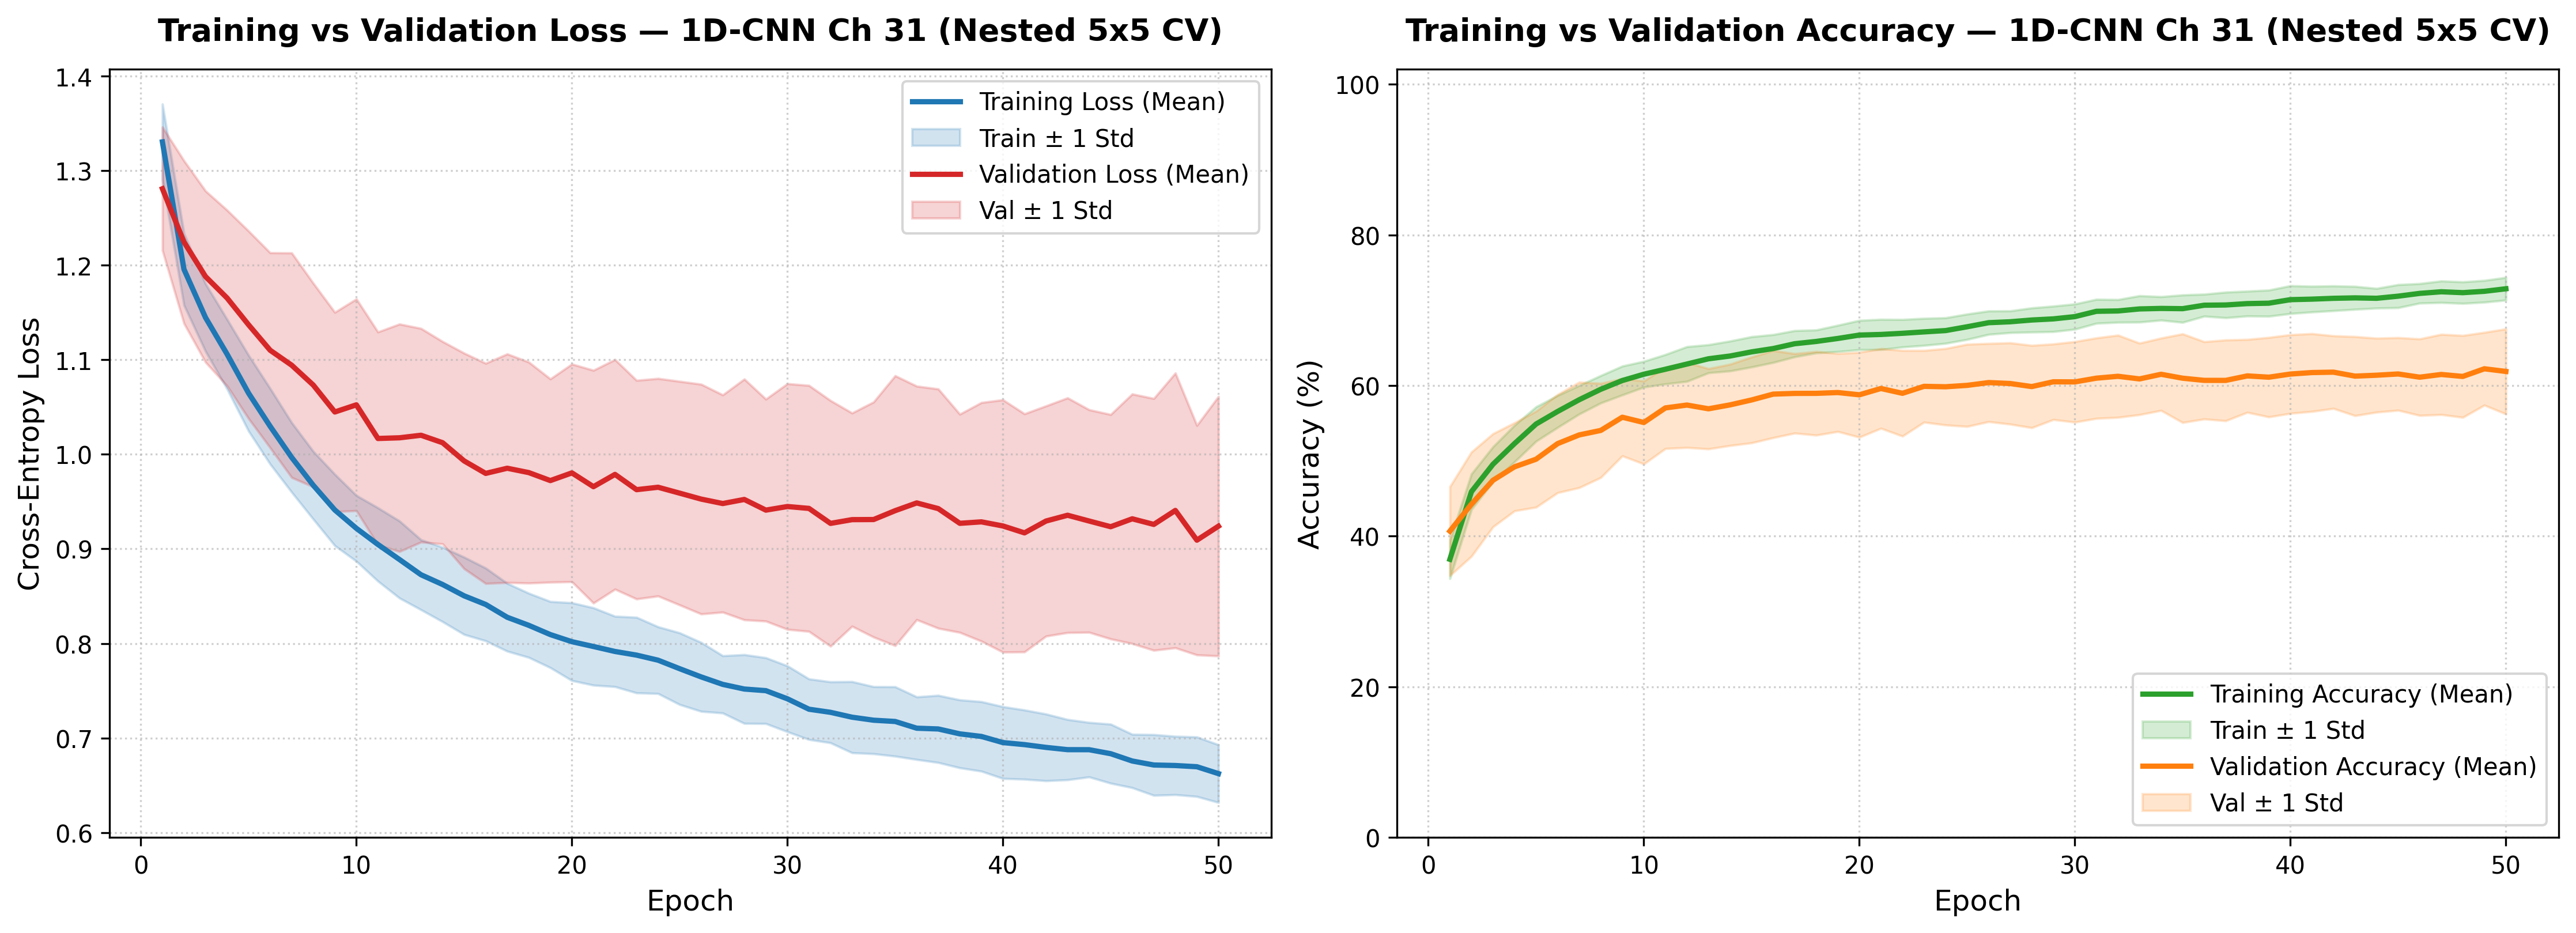

Saved confusion matrix to: /content/drive/MyDrive/results/baseline_1dcnn_ch31_confusion_matrix.png


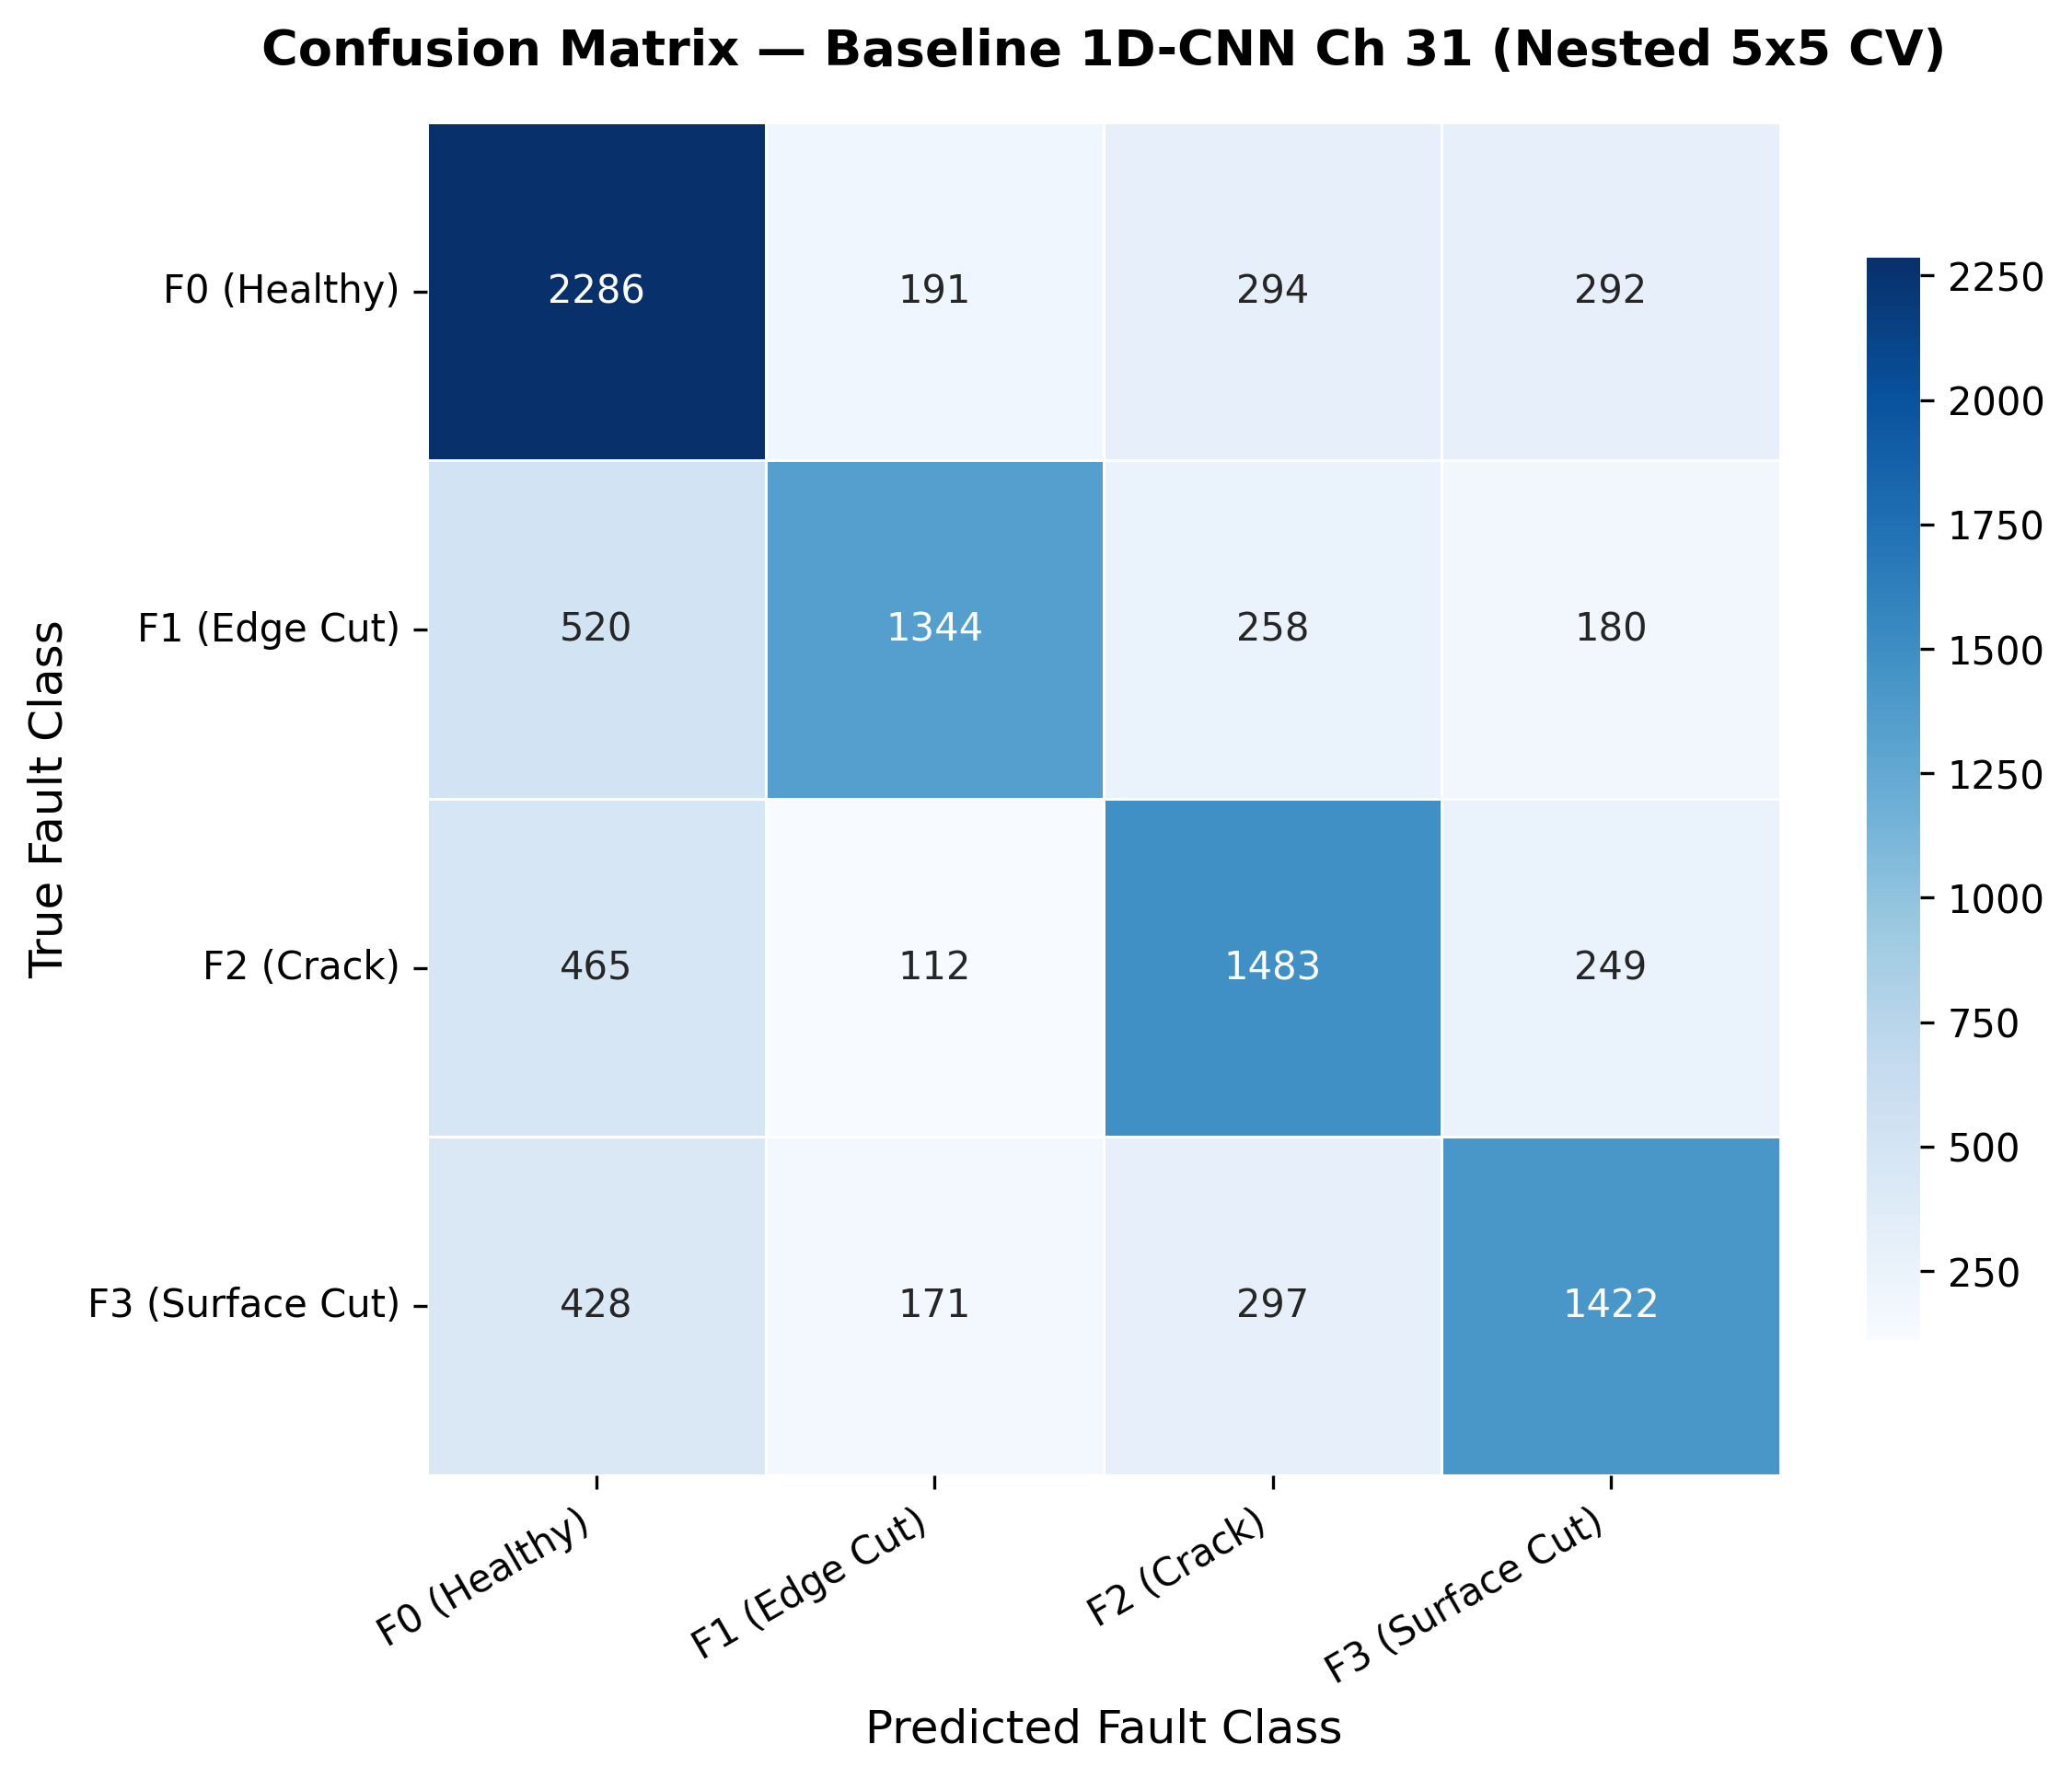

Saved classification report to: /content/drive/MyDrive/results/baseline_1dcnn_ch31_classification_report.png


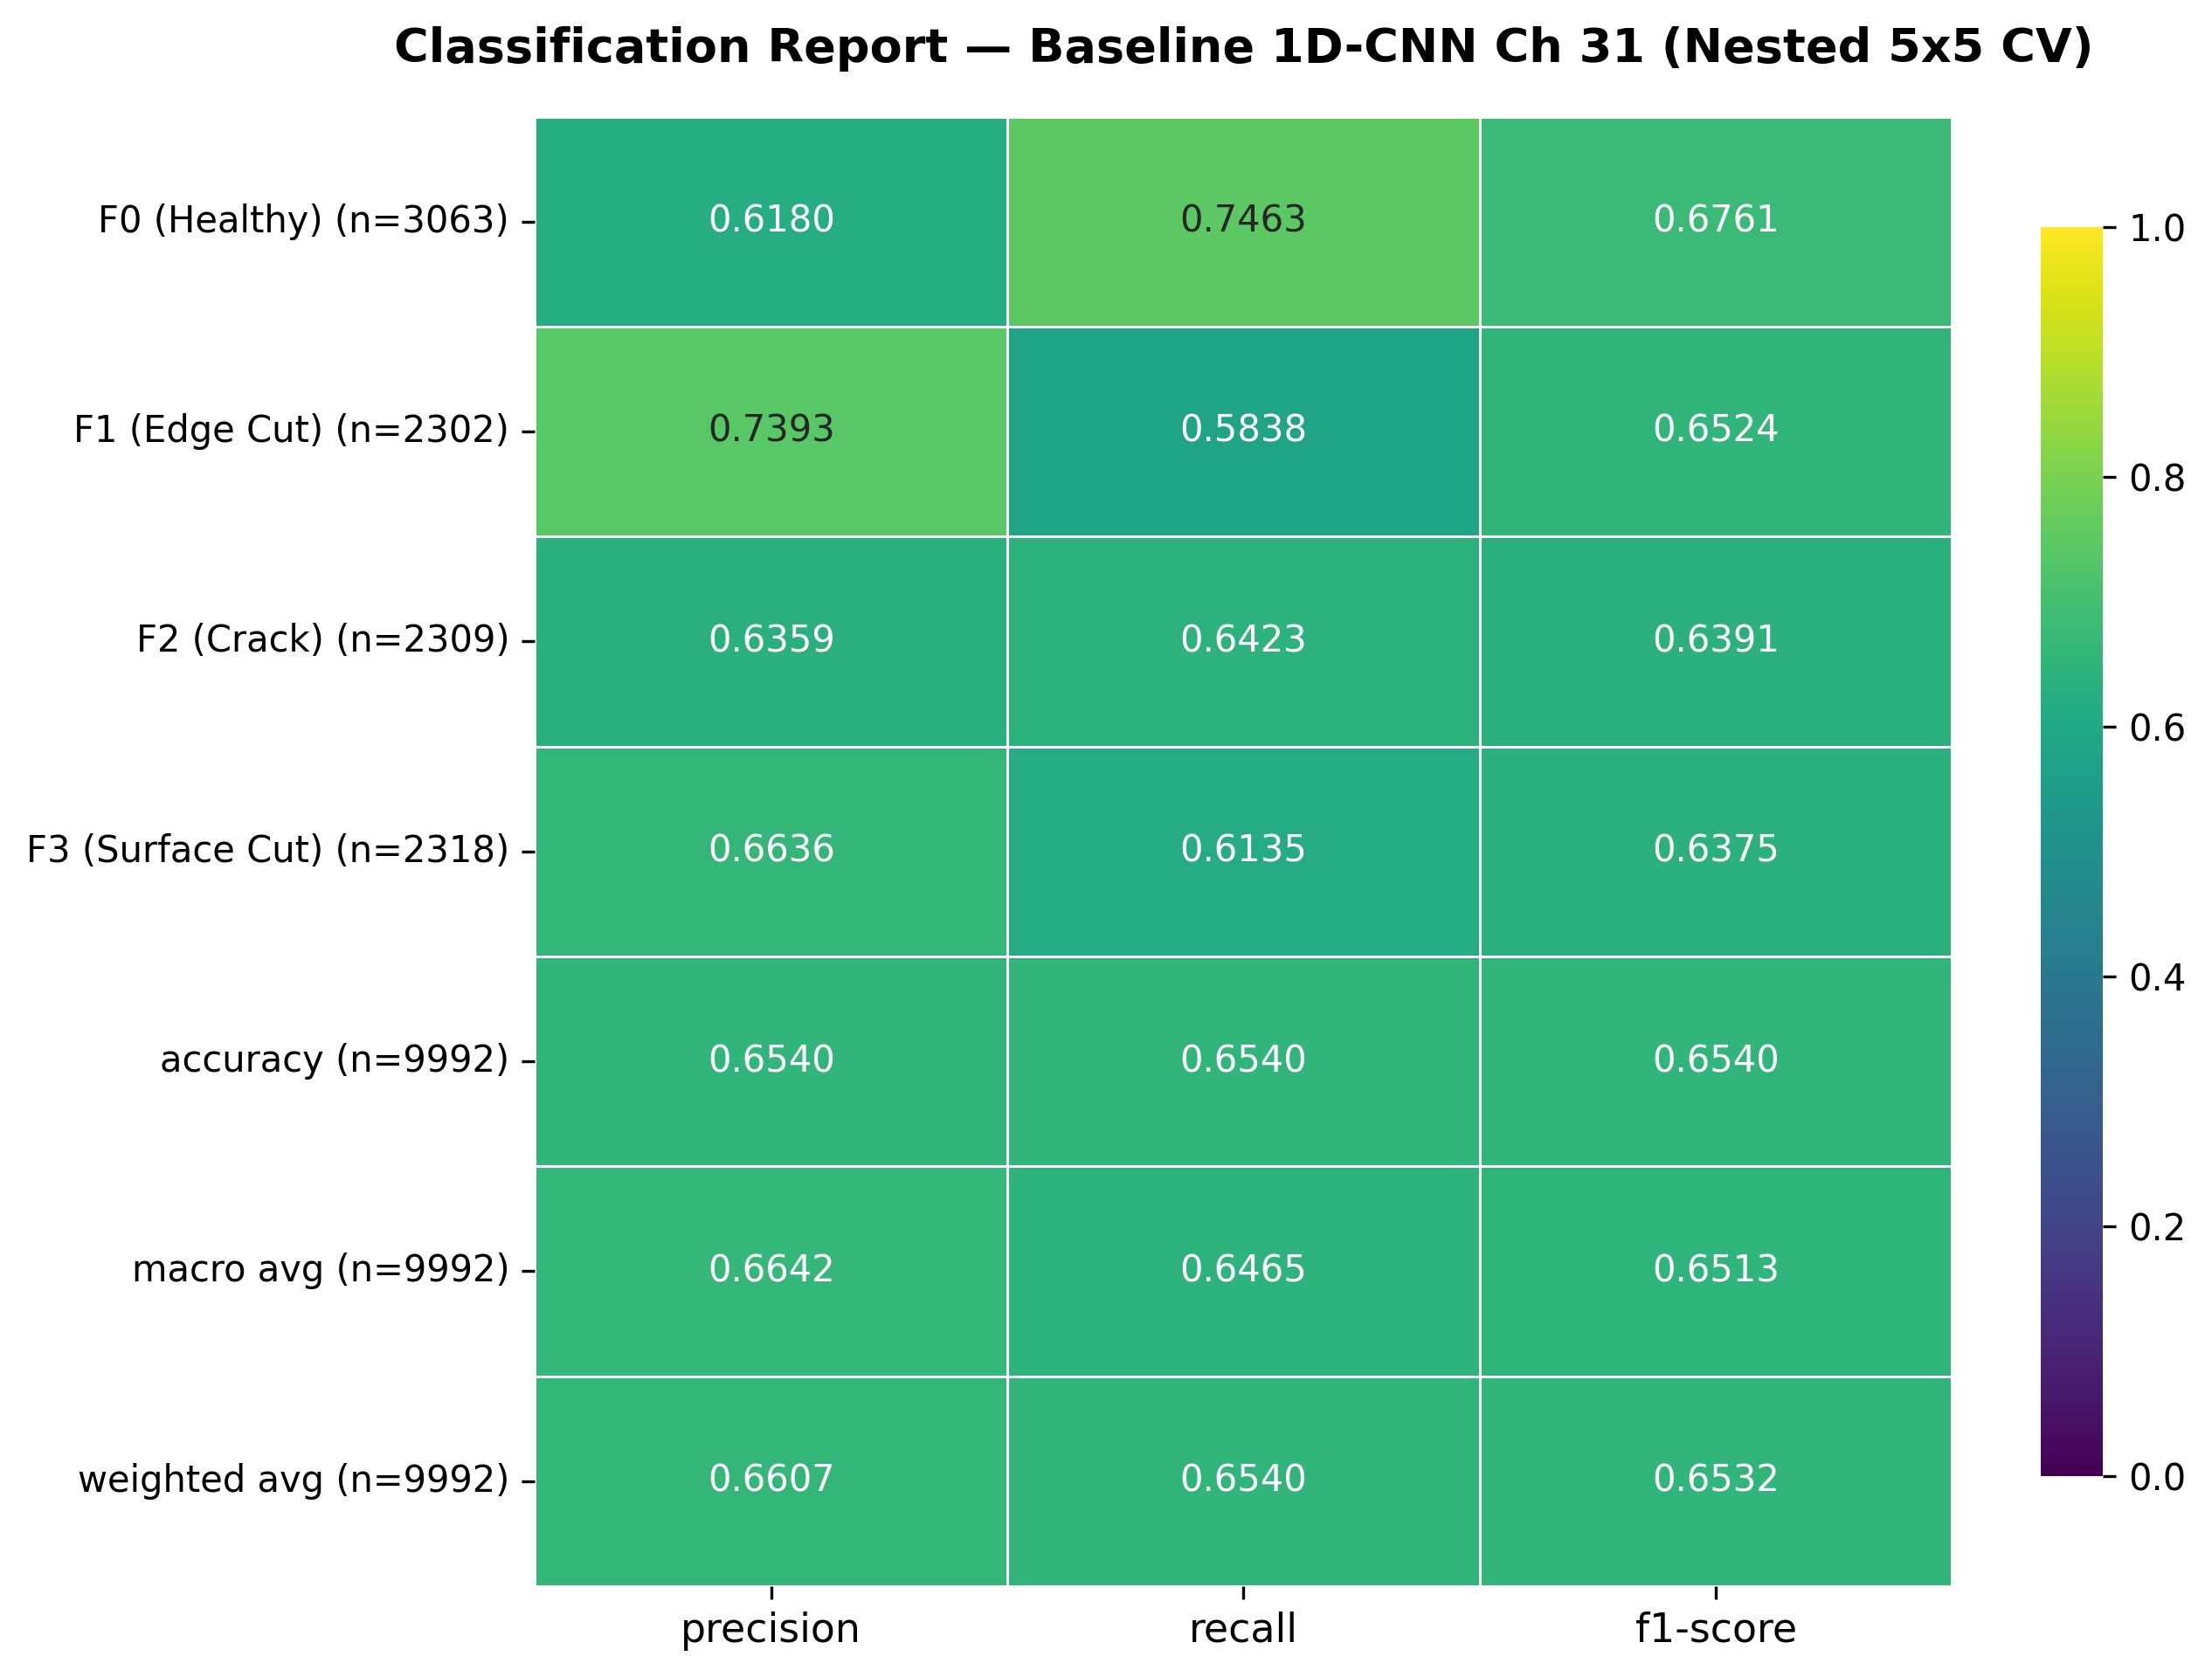

Computing t-SNE on (1964, 32) features from Outer Fold 3 / Inner Fold 2...
Saved t-SNE plot to: /content/drive/MyDrive/results/baseline_1dcnn_ch31_tsne.png


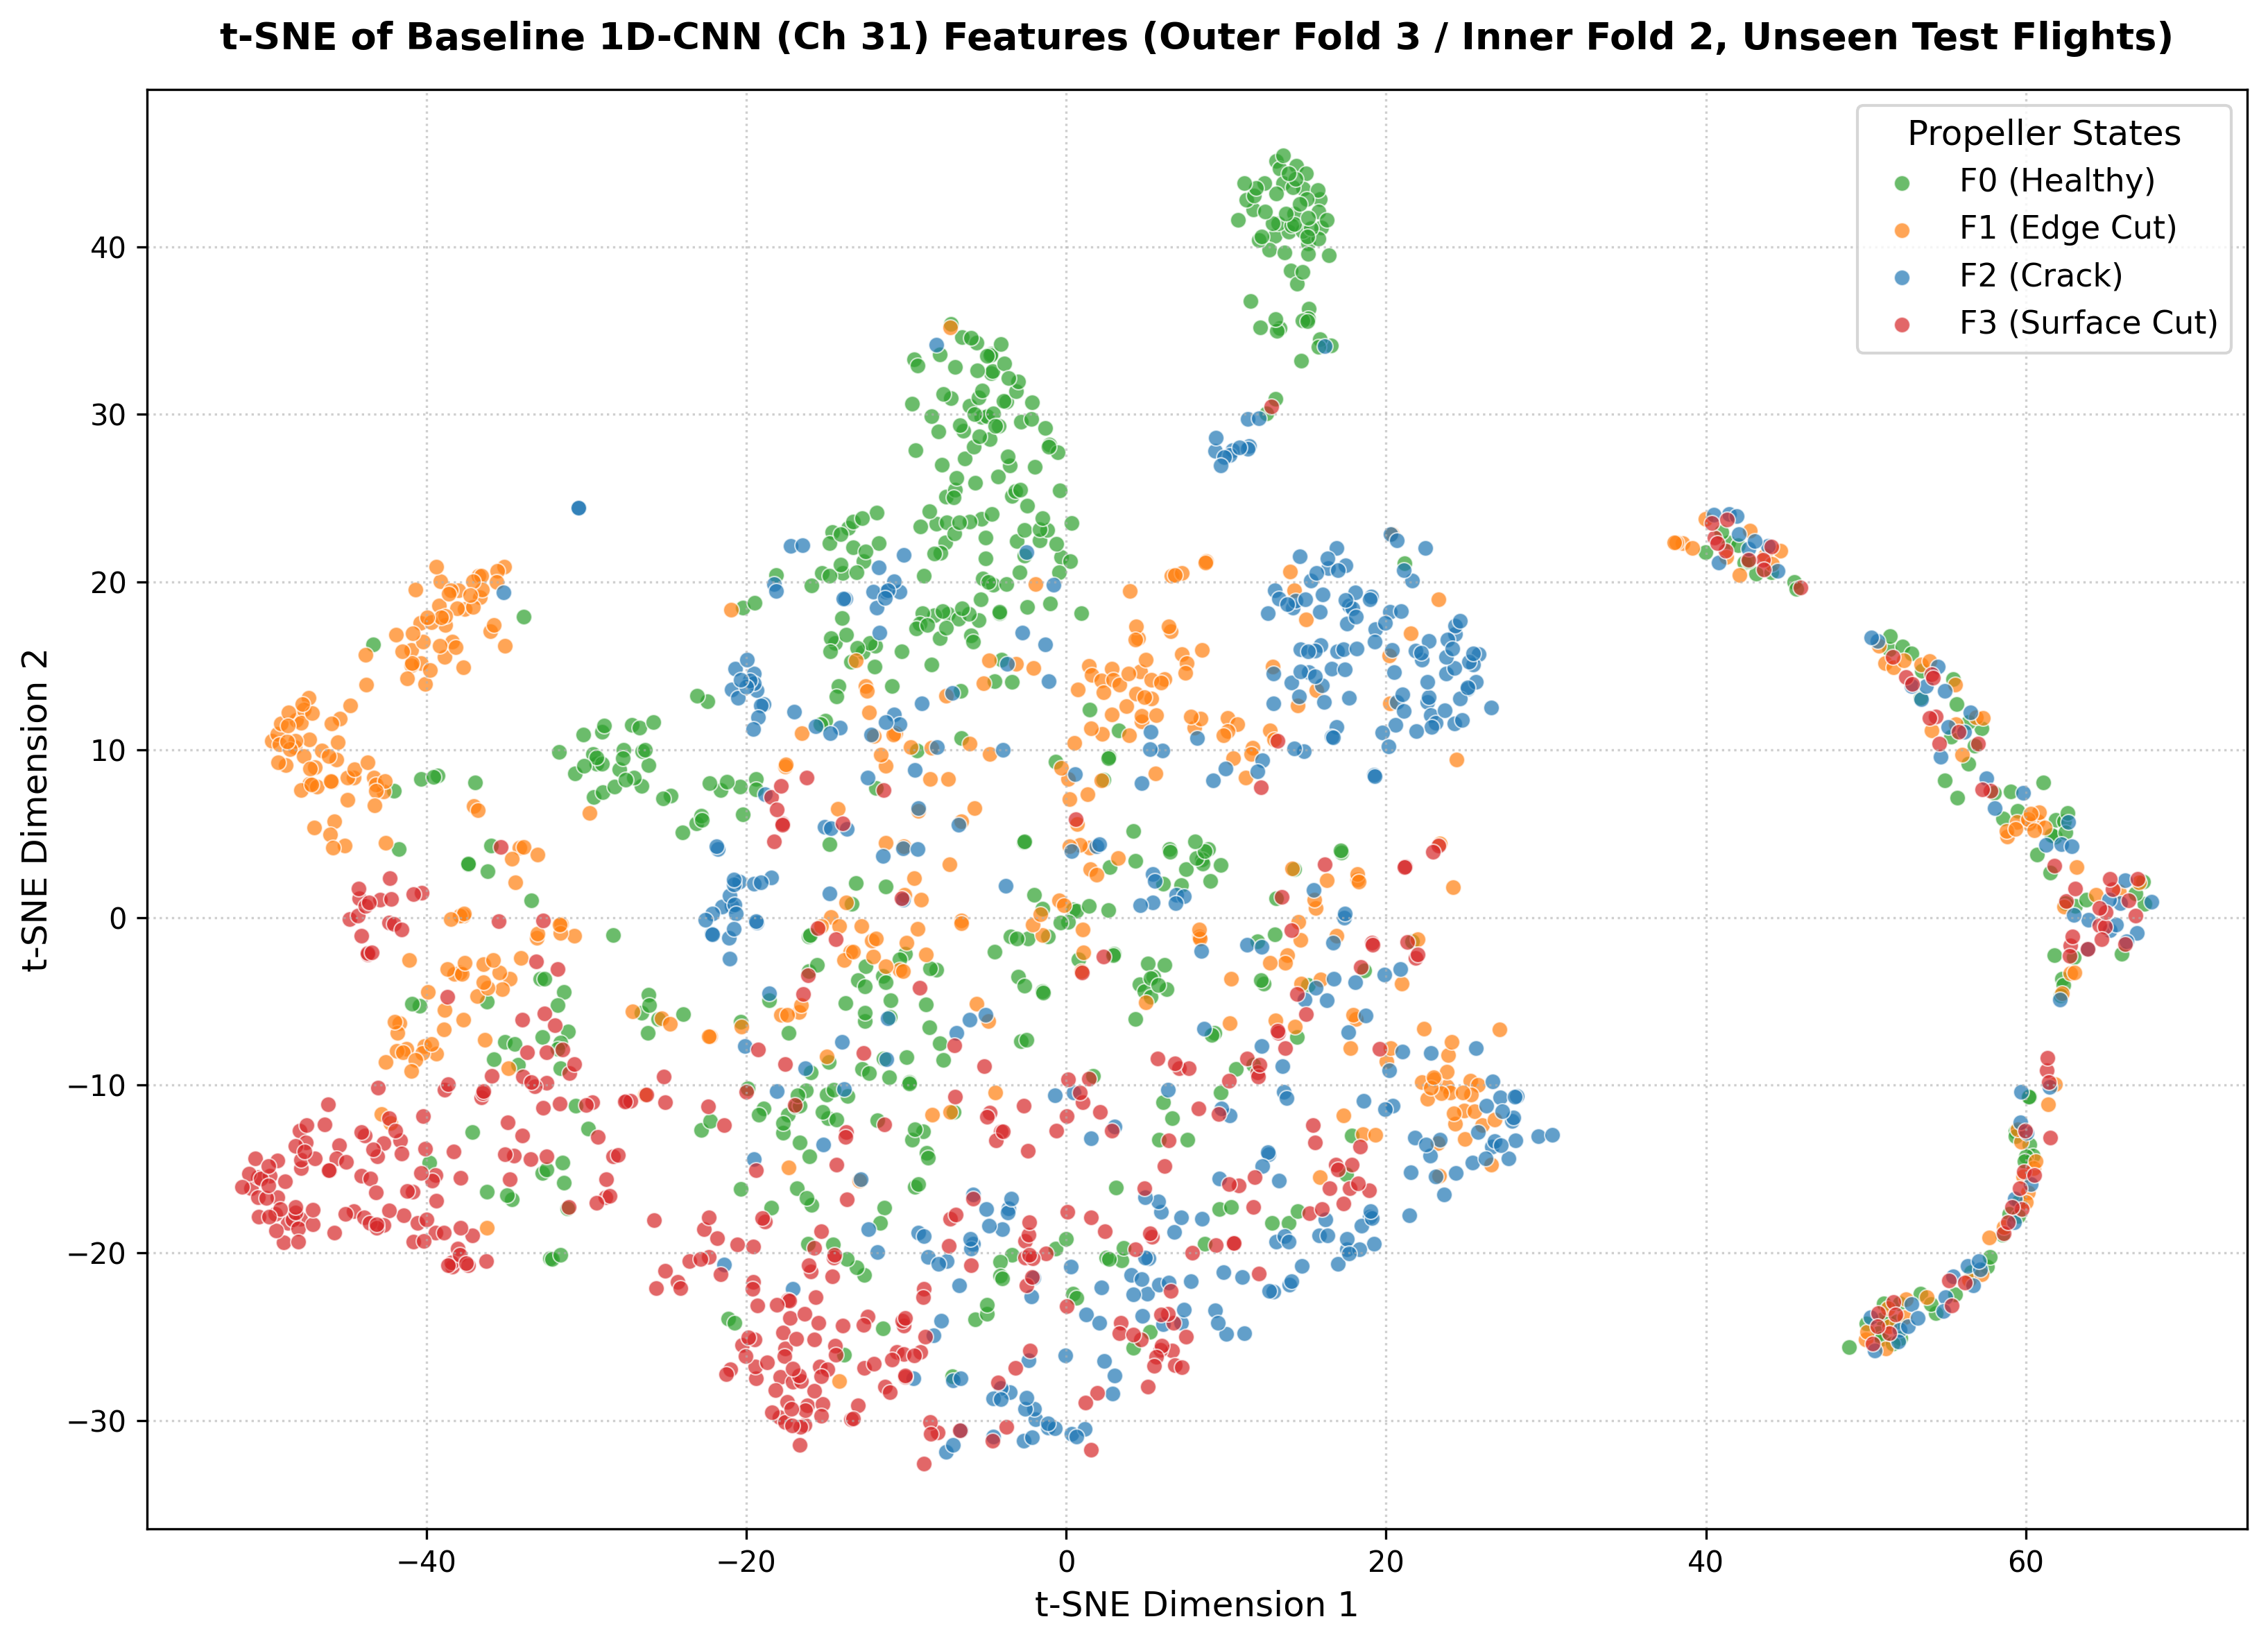

In [3]:
import os

save_dir = "/content/drive/MyDrive/results"
os.makedirs(save_dir, exist_ok=True)

plot_learning_curves(
    history,
    save_path=f"{save_dir}/baseline_1dcnn_ch31_learning_curves.png"
)
plot_colorful_metrics(
    y_true_oof,
    y_pred_oof,
    class_names=class_names,
    cm_path=f"{save_dir}/baseline_1dcnn_ch31_confusion_matrix.png",
    cr_path=f"{save_dir}/baseline_1dcnn_ch31_classification_report.png"
)
plot_tsne_from_bundle(
    tsne_bundle,
    class_names=class_names,
    save_path=f"{save_dir}/baseline_1dcnn_ch31_tsne.png"
)